# Análise de Crédito – CredAIR
Investigação dos fatores relacionados à inadimplência e desenvolvimento de um modelo de Regressão Logística para apoiar a identificação de propostas de maior risco.

## 1. Carregamento dos dados
Bibliotecas usadas na análise e leitura do arquivo `credito.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/credito.csv")
df.head()

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1


In [3]:
df = pd.read_csv("../data/credito.csv")

### Estrutura do dataset
Verificação da quantidade de registros, dos tipos das colunas e de valores ausentes.

In [4]:
print(df.shape)
df.info()

(5000, 11)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               5000 non-null   int64  
 1   estado              5000 non-null   str    
 2   escolaridade        5000 non-null   str    
 3   renda_mensal        5000 non-null   float64
 4   tempo_emprego_anos  5000 non-null   int64  
 5   score_credito       5000 non-null   int64  
 6   valor_solicitado    5000 non-null   float64
 7   prazo_meses         5000 non-null   int64  
 8   finalidade          5000 non-null   str    
 9   dividas_ativas      5000 non-null   int64  
 10  inadimplente        5000 non-null   int64  
dtypes: float64(2), int64(6), str(3)
memory usage: 429.8 KB


O dataset tem 5.000 propostas e 11 colunas. Nenhuma coluna tem valores nulos e os tipos estão corretos. 
Isso não garante que os dados estejam limpos: ausentes podem estar representados por valores como 0 ou -1, 
o que será verificado a seguir.

### Estatísticas das variáveis numéricas
Análise de mínimos e máximos para identificar valores impossíveis ou fora da faixa esperada.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.767400,31.646099,18.00,32.00,46.00,61.0000,750.00
renda_mensal,5000.0,5228.633582,3968.478198,100.00,2697.32,4146.30,6458.8775,44814.19
tempo_emprego_anos,5000.0,12.662200,7.517539,1.00,6.00,13.00,19.0000,74.00
score_credito,5000.0,652.481200,84.817076,335.00,594.00,653.00,710.0000,850.00
valor_solicitado,5000.0,14264.657378,8268.261465,1721.48,8467.17,12365.63,17764.8850,50000.00
prazo_meses,5000.0,29.922000,15.482515,6.00,18.00,24.00,36.0000,60.00
dividas_ativas,5000.0,1.900400,1.864719,0.00,0.00,1.00,3.0000,7.00
inadimplente,5000.0,0.344000,0.475089,0.00,0.00,0.00,1.0000,1.00


### Categorias das variáveis de texto
Verificação das categorias existentes e de possíveis grafias diferentes para o mesmo valor.

In [6]:
for col in ["estado", "escolaridade", "finalidade"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- estado ---
estado
DF        205
SC        197
MG        197
GO        195
PB        195
         ... 
  PB        1
  AM        1
 MG         1
 SE         1
  RR        1
Name: count, Length: 85, dtype: int64

--- escolaridade ---
escolaridade
Ensino Médio          2061
Ensino Superior       1938
Pós-graduação          590
Ensino Fundamental     411
Name: count, dtype: int64

--- finalidade ---
finalidade
Veículo     1128
Reforma     1117
Outros       941
Educação     709
Saúde        611
Viagem       494
Name: count, dtype: int64



In [7]:
print(df["estado"].nunique())
print(sorted(df["estado"].unique()))

85
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


A coluna `estado` apresenta 85 valores distintos, embora existam apenas 27 UFs. 
Há siglas com espaços extras (ex.: " MG"), que serão padronizadas na etapa de limpeza.

### Investigação dos valores suspeitos
Quantificação dos problemas indicados pelas estatísticas descritivas.

In [8]:
print("Idade > 100:", (df["idade"] > 100).sum())
print(df.loc[df["idade"] > 100, "idade"].value_counts())
print()
print("Renda igual a 100:", (df["renda_mensal"] == 100).sum())
print("Valor solicitado igual a 50.000:", (df["valor_solicitado"] == 50000).sum())
print("Tempo de emprego incompatível com a idade:", (df["tempo_emprego_anos"] > df["idade"] - 14).sum())
print()
print("Prazos existentes:", sorted(df["prazo_meses"].unique()))
print("Linhas duplicadas:", df.duplicated().sum())

Idade > 100: 15
idade
660    1
680    1
710    1
430    1
300    1
360    1
440    1
280    1
500    1
340    1
210    1
540    1
700    1
750    1
670    1
Name: count, dtype: int64

Renda igual a 100: 1
Valor solicitado igual a 50.000: 32
Tempo de emprego incompatível com a idade: 696

Prazos existentes: [np.int64(6), np.int64(12), np.int64(18), np.int64(24), np.int64(36), np.int64(48), np.int64(60)]
Linhas duplicadas: 19


### Resumo do diagnóstico

- 15 idades acima de 100, todas múltiplas de 10 (provável zero a mais na digitação);
- 696 registros com tempo de emprego incompatível com a idade;
- 85 valores distintos em `estado` por causa de espaços extras;
- 19 linhas duplicadas;
- 32 propostas no valor máximo de R\$ 50.000, provavelmente o teto de crédito (não é erro);
- 1 renda de R\$ 100, caso isolado.

Esses pontos serão tratados na etapa de limpeza.

## Limpeza dos dados

A limpeza é feita em uma cópia do DataFrame. O original fica intacto para comparar o antes e o depois de cada tratamento.

In [9]:
df_limpo = df.copy()

print(f"Linhas: {df_limpo.shape[0]} | Colunas: {df_limpo.shape[1]}")

Linhas: 5000 | Colunas: 11


### Padronização da coluna estado

A coluna tinha 85 valores distintos em vez de 27 UFs, por causa de espaços extras. Os espaços são removidos e as siglas ficam em maiúsculas.

In [10]:
df_limpo["estado"] = df_limpo["estado"].str.strip().str.upper()

print(f"Valores distintos: {df_limpo['estado'].nunique()}")
print(sorted(df_limpo["estado"].unique()))

Valores distintos: 27
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


### Verificação de duplicatas

Na inspeção inicial havia 19 linhas duplicadas. Após padronizar o estado, a contagem é refeita, pois linhas que diferiam só por espaços na sigla agora podem ser idênticas.

In [11]:
print(f"Duplicatas antes da padronização: {df.duplicated().sum()}")
print(f"Duplicatas após a padronização: {df_limpo.duplicated().sum()}")

Duplicatas antes da padronização: 19
Duplicatas após a padronização: 19


Mesmo após a padronização, as duplicatas continuam sendo 19. São linhas idênticas em todas as 11 colunas, inclusive na renda com centavos, o que torna improvável serem propostas diferentes que coincidiram por acaso. Elas são tratadas como registros repetidos e removidas, mantendo a primeira ocorrência.

In [12]:
df_limpo = df_limpo.drop_duplicates().reset_index(drop=True)

print(f"Linhas após remover duplicatas: {df_limpo.shape[0]}")

Linhas após remover duplicatas: 4981


### Idades acima de 100

Há registros com idade entre 210 e 750, todos múltiplos de 10. A hipótese é um zero a mais na digitação. Para testar, a idade dividida por 10 é comparada com o tempo de emprego de cada registro.

In [13]:
idades_invalidas = df_limpo[df_limpo["idade"] > 100]

print(f"Registros com idade acima de 100: {len(idades_invalidas)}")

idades_invalidas.assign(idade_corrigida=idades_invalidas["idade"] // 10)[
    ["idade", "idade_corrigida", "tempo_emprego_anos"]
]

Registros com idade acima de 100: 15


,idade,idade_corrigida,tempo_emprego_anos
482,660,66,7
697,680,68,20
924,710,71,15
974,430,43,10
986,300,30,19
1217,360,36,4
1260,440,44,18
1287,280,28,5
1504,500,50,2
2666,340,34,8


A divisão por 10 gera idades entre 21 e 75, e em 14 dos 15 casos a idade corrigida é compatível com o tempo de emprego. Isso reforça a hipótese de erro de digitação. As idades são corrigidas em vez de imputadas, pois o valor real pode ser recuperado. A correção usa apenas o próprio registro, sem estatísticas da base.

In [14]:
mascara_idade = df_limpo["idade"] > 100

df_limpo.loc[mascara_idade, "idade"] = df_limpo.loc[mascara_idade, "idade"] // 10

print(f"Idade mínima: {df_limpo['idade'].min()} | Idade máxima: {df_limpo['idade'].max()}")

Idade mínima: 18 | Idade máxima: 75


### Tempo de emprego incompatível com a idade

Com as idades corrigidas, a verificação do tempo de emprego é refeita. Considera-se 14 anos como idade mínima para começar a trabalhar (aprendiz). Registros com tempo de emprego maior que idade − 14 são incompatíveis.

In [15]:
IDADE_MINIMA_TRABALHO = 14

tempo_maximo_possivel = df_limpo["idade"] - IDADE_MINIMA_TRABALHO
mascara_emprego = df_limpo["tempo_emprego_anos"] > tempo_maximo_possivel

print(f"Registros incompatíveis: {mascara_emprego.sum()} ({mascara_emprego.mean():.1%} da base)")

Registros incompatíveis: 694 (13.9% da base)


São 694 registros incompatíveis (13,9% da base). Antes de decidir o tratamento, os dois grupos são comparados em idade, tempo de emprego e taxa de inadimplência.

In [16]:
df_limpo.groupby(mascara_emprego).agg(
    quantidade=("idade", "size"),
    idade_media=("idade", "mean"),
    tempo_emprego_medio=("tempo_emprego_anos", "mean"),
    taxa_inadimplencia=("inadimplente", "mean"),
).round(2)

,quantidade,idade_media,tempo_emprego_medio,taxa_inadimplencia
False,4287,49.71,11.75,0.35
True,694,26.13,18.28,0.33


Os registros incompatíveis são de pessoas mais jovens (26 anos em média, contra 50), e a taxa de inadimplência é parecida nos dois grupos (33% contra 35%). Remover 14% da base, concentrada em jovens, deixaria esse público sub-representado. Imputar pela mediana também geraria valores impossíveis para jovens.

O tempo de emprego é limitado ao máximo possível (idade − 14), usando só o próprio registro, sem risco de vazamento. A coluna `tempo_emprego_ajustado` marca os registros alterados.

In [17]:
df_limpo["tempo_emprego_ajustado"] = mascara_emprego.astype(int)

df_limpo.loc[mascara_emprego, "tempo_emprego_anos"] = tempo_maximo_possivel[mascara_emprego]

incompativeis_restantes = (df_limpo["tempo_emprego_anos"] > df_limpo["idade"] - IDADE_MINIMA_TRABALHO).sum()
print(f"Registros ajustados: {df_limpo['tempo_emprego_ajustado'].sum()}")
print(f"Incompatíveis restantes: {incompativeis_restantes}")

Registros ajustados: 694
Incompatíveis restantes: 0


### Renda mensal mínima

Um único registro tem renda de R\$ 100,00. Para avaliar se é erro, ele é comparado com as menores rendas da base.

In [18]:
df_limpo.nsmallest(5, "renda_mensal")

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente,tempo_emprego_ajustado
2621,49,AL,Ensino Médio,100.0,12,766,20001.16,24,Educação,0,0,0
4851,59,MA,Ensino Fundamental,150.0,20,636,25384.28,24,Veículo,1,1,0
4778,57,GO,Ensino Superior,200.0,5,775,12576.22,60,Educação,0,0,0
431,18,AC,Ensino Médio,250.0,1,746,15819.19,36,Saúde,0,1,0
608,21,DF,Pós-graduação,300.0,7,616,9018.23,60,Saúde,0,1,1


As menores rendas formam uma sequência de valores redondos (100, 150, 200, 250 e 300 reais), diferente do restante da base, que tem centavos. Para entender o padrão, as rendas abaixo de 1.000 reais são analisadas.

In [19]:
renda_baixa = df_limpo[df_limpo["renda_mensal"] < 1000]

print(f"Registros com renda abaixo de R$ 1.000: {len(renda_baixa)}")
print(f"Desses, valores múltiplos de 50: {(renda_baixa['renda_mensal'] % 50 == 0).sum()}")

renda_baixa["renda_mensal"].value_counts().sort_index()

Registros com renda abaixo de R$ 1.000: 64
Desses, valores múltiplos de 50: 44


renda_mensal
100.00     1
150.00     1
200.00     1
250.00     1
300.00     1
350.00     1
400.00     1
450.00     1
500.00     1
550.00     1
900.00    34
902.95     1
908.20     1
908.42     1
910.10     1
913.40     1
918.92     1
922.57     1
923.04     1
929.09     1
932.54     1
946.57     1
952.10     1
959.03     1
959.83     1
960.17     1
961.10     1
977.24     1
983.92     1
992.62     1
998.09     1
Name: count, dtype: int64

As rendas abaixo de 1.000 reais mostram dois padrões. Há 34 registros com exatamente 900 reais, que funcionam como piso da renda (acima disso os valores têm centavos) e são mantidos. Há também 10 registros de 100 a 550 reais, em sequência de 50 em 50, abaixo do piso. Esses são considerados inválidos e removidos, pois representam só 0,2% da base.

In [20]:
RENDA_PISO = 900

mascara_renda = df_limpo["renda_mensal"] < RENDA_PISO
print(f"Registros com renda inválida: {mascara_renda.sum()}")

df_limpo = df_limpo[~mascara_renda].reset_index(drop=True)
print(f"Linhas após a remoção: {df_limpo.shape[0]}")

Registros com renda inválida: 10
Linhas após a remoção: 4971


### Valor solicitado

Na inspeção inicial, vários registros tinham exatamente 50 mil reais, o maior valor da base. Um acúmulo exato no máximo indica um teto de crédito da empresa, e não erro de digitação.

In [21]:
valor_maximo = df_limpo["valor_solicitado"].max()
no_teto = df_limpo["valor_solicitado"] == valor_maximo

print(f"Valor máximo: {valor_maximo:,.2f}")
print(f"Registros no teto: {no_teto.sum()}")
print(f"Maior valor abaixo do teto: {df_limpo.loc[~no_teto, 'valor_solicitado'].max():,.2f}")

Valor máximo: 50,000.00
Registros no teto: 32
Maior valor abaixo do teto: 49,922.11


### Valores ausentes e tipos

A base não tem valores nulos explícitos, e nenhum tratamento anterior gerou ausentes: as idades foram corrigidas, o tempo de emprego foi limitado e as rendas inválidas foram removidas. A verificação final confirma isso e os tipos das colunas.

In [22]:
df_limpo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4971 entries, 0 to 4970
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   idade                   4971 non-null   int64  
 1   estado                  4971 non-null   str    
 2   escolaridade            4971 non-null   str    
 3   renda_mensal            4971 non-null   float64
 4   tempo_emprego_anos      4971 non-null   int64  
 5   score_credito           4971 non-null   int64  
 6   valor_solicitado        4971 non-null   float64
 7   prazo_meses             4971 non-null   int64  
 8   finalidade              4971 non-null   str    
 9   dividas_ativas          4971 non-null   int64  
 10  inadimplente            4971 non-null   int64  
 11  tempo_emprego_ajustado  4971 non-null   int64  
dtypes: float64(2), int64(7), str(3)
memory usage: 466.2 KB


### Resumo da limpeza

| Problema | Decisão | Motivo |
|---|---|---|
| Estado com espaços extras (85 valores distintos) | Remoção de espaços e conversão para maiúsculas | Restaurar as 27 UFs |
| 19 linhas duplicadas | Remoção | Idênticas em todas as colunas, inclusive na renda com centavos |
| 15 idades acima de 100 | Divisão por 10 | Todas múltiplas de 10; corrigidas ficam entre 21 e 75 e coerentes com o tempo de emprego |
| 694 registros com tempo de emprego maior que idade − 14 | Limite em idade − 14 e coluna `tempo_emprego_ajustado` | Remover eliminaria 14% da base, concentrada em jovens; a correção usa só o próprio registro |
| 10 rendas entre 100 e 550 reais, em sequência de 50 em 50 | Remoção | Abaixo do piso de 900 reais e só 0,2% da base |
| 34 rendas de exatamente 900 reais | Mantidas | Piso da renda |
| 32 valores solicitados de 50 mil reais | Mantidos | Teto de crédito da empresa |

A base final tem 4971 linhas e 12 colunas, sem valores ausentes e com os tipos adequados. Os valores inválidos foram corrigidos ou removidos em vez de imputados, para não criar valores artificiais nem arriscar vazamento de dados.

## Análise exploratória

### Distribuição do alvo

Proporção de adimplentes e inadimplentes na base limpa. Na base original, a inadimplência era de 34,4%.

,quantidade,percentual
Adimplente,3261,65.6
Inadimplente,1710,34.4


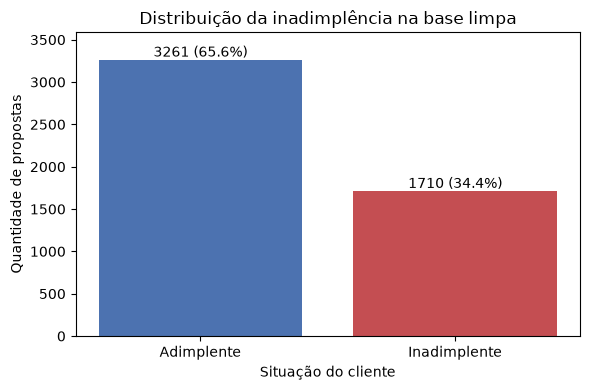

In [23]:
contagem_alvo = df_limpo["inadimplente"].value_counts().sort_index()
percentual_alvo = df_limpo["inadimplente"].value_counts(normalize=True).sort_index() * 100

resumo_alvo = pd.DataFrame({
    "quantidade": contagem_alvo,
    "percentual": percentual_alvo.round(1)
})
resumo_alvo.index = ["Adimplente", "Inadimplente"]
display(resumo_alvo)

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(resumo_alvo.index, resumo_alvo["quantidade"], color=["#4C72B0", "#C44E52"])
rotulos = [f"{q} ({p:.1f}%)" for q, p in zip(resumo_alvo["quantidade"], resumo_alvo["percentual"])]
ax.bar_label(barras, labels=rotulos)
ax.margins(y=0.1)
ax.set_title("Distribuição da inadimplência na base limpa")
ax.set_xlabel("Situação do cliente")
ax.set_ylabel("Quantidade de propostas")
plt.tight_layout()
plt.show()

A base limpa tem 1.710 inadimplentes (34,4%) e 3.261 adimplentes (65,6%), a mesma proporção da base original. A limpeza não alterou o equilíbrio do alvo.

As classes são desbalanceadas, quase 2 para 1. Um modelo que previsse sempre "adimplente" acertaria 65,6% dos casos, então a acurácia sozinha não basta para avaliar o modelo.

### Variáveis numéricas

Resumo estatístico das variáveis numéricas da base limpa.

In [24]:
colunas_numericas = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito",
                     "valor_solicitado", "prazo_meses", "dividas_ativas"]

df_limpo[colunas_numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
idade,4971.0,46.43,16.79,18.00,32.00,46.00,61.00,75.00
renda_mensal,4971.0,5238.84,3968.13,900.00,2704.04,4153.69,6465.97,44814.19
tempo_emprego_anos,4971.0,11.80,7.11,1.00,6.00,11.00,17.00,59.00
score_credito,4971.0,652.37,84.82,335.00,594.00,653.00,710.00,850.00
valor_solicitado,4971.0,14258.93,8267.69,1721.48,8466.86,12362.65,17758.87,50000.00
prazo_meses,4971.0,29.90,15.48,6.00,18.00,24.00,36.00,60.00
dividas_ativas,4971.0,1.90,1.87,0.00,0.00,1.00,3.00,7.00


Idade e score de crédito têm distribuição simétrica (média próxima da mediana). Renda mensal e valor solicitado são assimétricas à direita: a maioria dos clientes fica em valores baixos e poucos casos altos puxam a média para cima.

As variáveis estão em escalas muito diferentes (renda na casa dos milhares, dívidas ativas de 0 a 7), o que deve ser considerado na preparação para o modelo.

Distribuição de cada variável numérica.

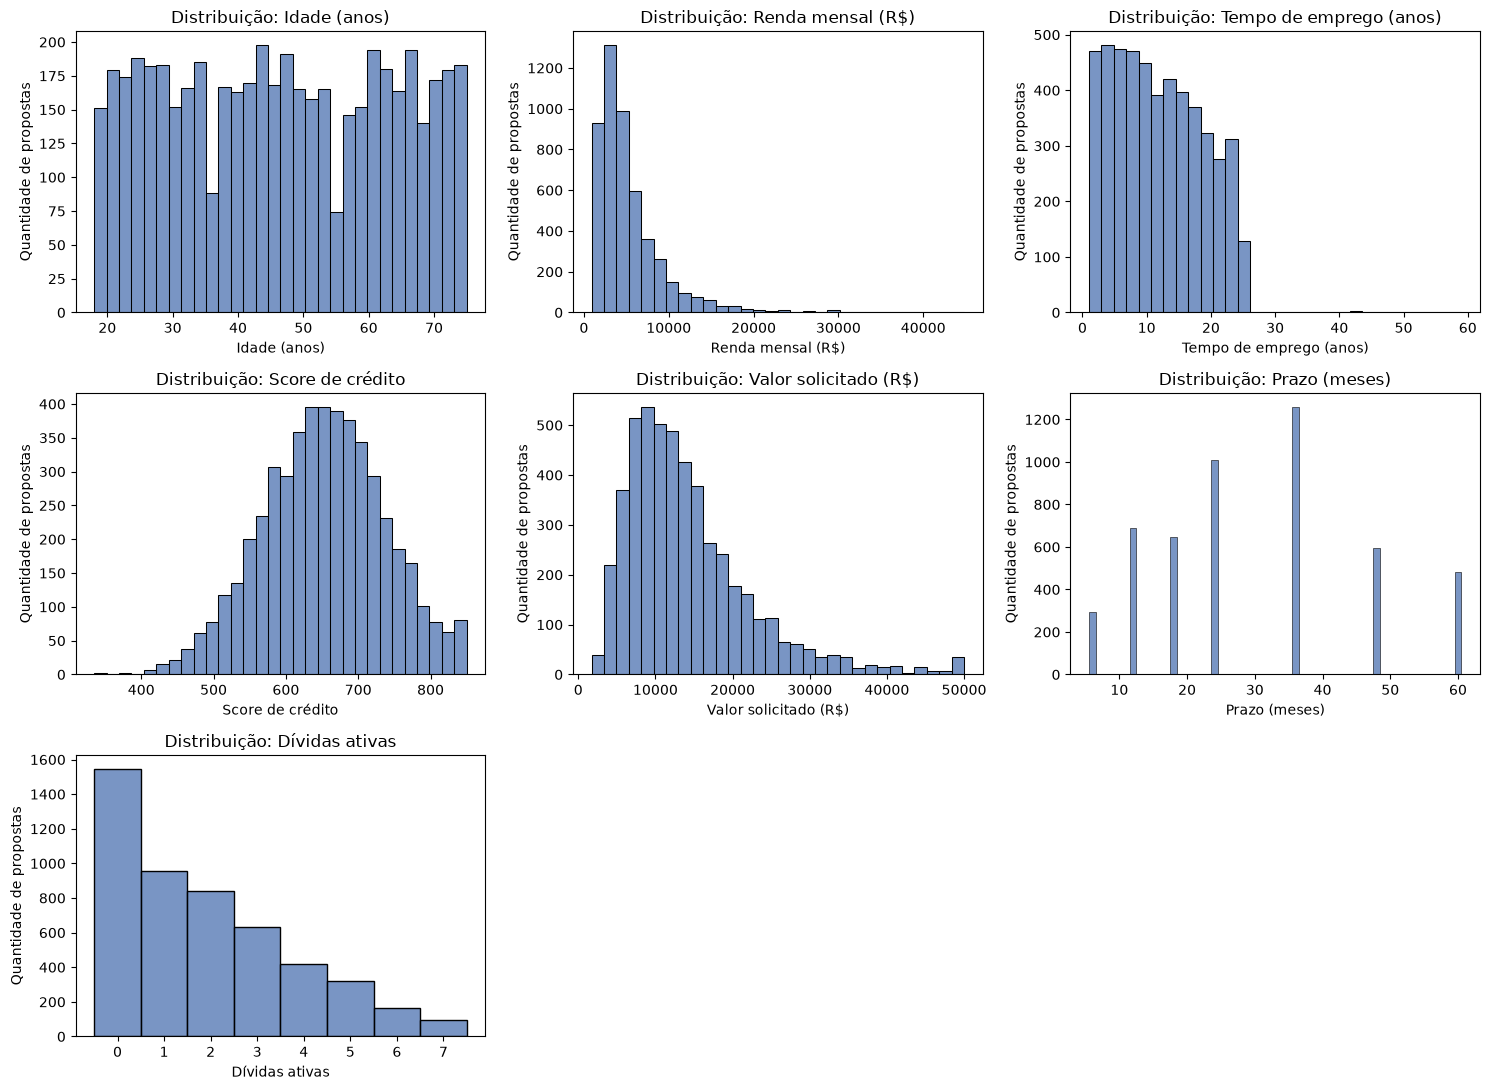

In [25]:
nomes_variaveis = {
    "idade": "Idade (anos)",
    "renda_mensal": "Renda mensal (R$)",
    "tempo_emprego_anos": "Tempo de emprego (anos)",
    "score_credito": "Score de crédito",
    "valor_solicitado": "Valor solicitado (R$)",
    "prazo_meses": "Prazo (meses)",
    "dividas_ativas": "Dívidas ativas"
}
colunas_discretas = ["prazo_meses", "dividas_ativas"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, coluna in enumerate(colunas_numericas):
    ax = axes[i]
    if coluna in colunas_discretas:
        sns.histplot(data=df_limpo, x=coluna, discrete=True, ax=ax, color="#4C72B0")
    else:
        sns.histplot(data=df_limpo, x=coluna, bins=30, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribuição: {nomes_variaveis[coluna]}")
    ax.set_xlabel(nomes_variaveis[coluna])
    ax.set_ylabel("Quantidade de propostas")

for j in range(len(colunas_numericas), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

A idade se distribui de forma uniforme entre 18 e 75 anos, e o score de crédito tem formato próximo de uma curva normal, centrado em 650. Renda mensal e valor solicitado são assimétricas à direita, com o pico do valor solicitado em 50 mil reais causado pelo teto de crédito.

O prazo mais comum é de 36 meses, e a quantidade de clientes diminui conforme aumenta o número de dívidas ativas. O tempo de emprego fica quase todo entre 1 e 25 anos, com poucos casos isolados acima disso.

Verificação dos registros com tempo de emprego acima de 25 anos, que destoam do restante da distribuição.

In [26]:
tempo_alto = df_limpo[df_limpo["tempo_emprego_anos"] > 25]
print(f"Registros com tempo de emprego acima de 25 anos: {len(tempo_alto)}")

tempo_alto[["idade", "tempo_emprego_anos", "tempo_emprego_ajustado", "inadimplente"]].sort_values("tempo_emprego_anos")

Registros com tempo de emprego acima de 25 anos: 7


,idade,tempo_emprego_anos,tempo_emprego_ajustado,inadimplente
2651,45,31,1,0
388,56,42,1,0
2703,56,42,1,1
848,62,48,1,1
3152,64,50,1,0
4633,66,52,1,1
1931,73,59,1,0


Os 7 registros com tempo de emprego acima de 25 anos são todos casos ajustados na limpeza (tempo limitado a idade − 14). Em clientes mais velhos, esse limite gera valores acima da faixa natural da base, que vai de 1 a 25 anos. Por representarem apenas 0,14% da base, foram mantidos.

### Variáveis categóricas

Distribuição de escolaridade e finalidade do crédito.

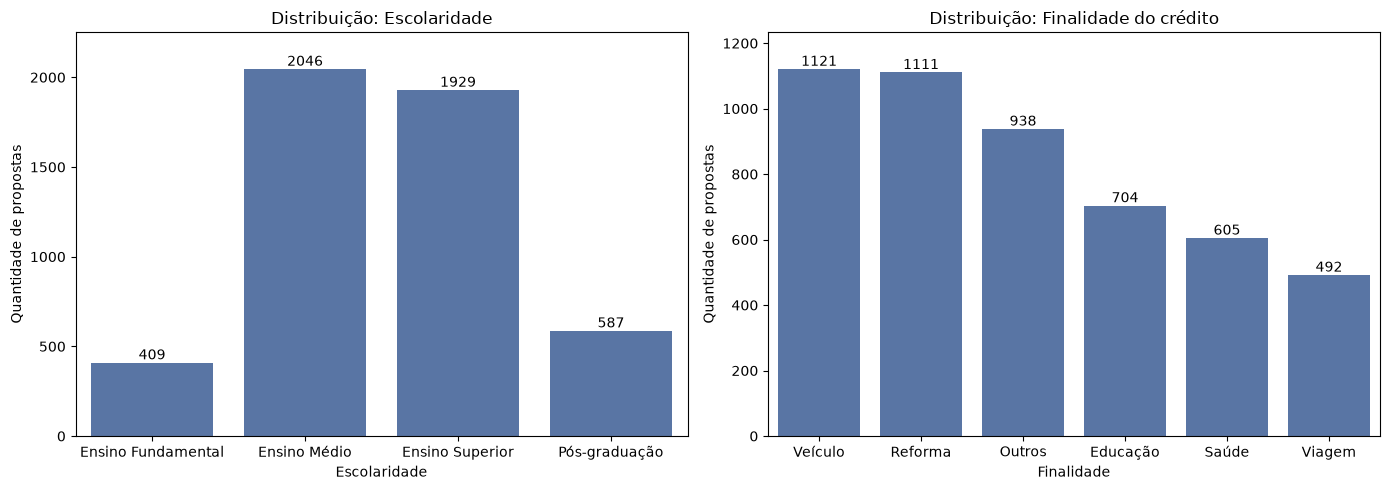

In [27]:
ordem_escolaridade = ["Ensino Fundamental", "Ensino Médio", "Ensino Superior", "Pós-graduação"]
ordem_finalidade = df_limpo["finalidade"].value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_limpo, x="escolaridade", order=ordem_escolaridade, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição: Escolaridade")
axes[0].set_xlabel("Escolaridade")
axes[0].set_ylabel("Quantidade de propostas")

sns.countplot(data=df_limpo, x="finalidade", order=ordem_finalidade, ax=axes[1], color="#4C72B0")
axes[1].set_title("Distribuição: Finalidade do crédito")
axes[1].set_xlabel("Finalidade")
axes[1].set_ylabel("Quantidade de propostas")

for ax in axes:
    ax.bar_label(ax.containers[0])
    ax.margins(y=0.1)

plt.tight_layout()
plt.show()

Ensino Médio e Ensino Superior concentram 80% dos clientes, enquanto Ensino Fundamental (8,2%) e Pós-graduação (11,8%) são minoria. Na finalidade, Veículo e Reforma lideram com cerca de 22% cada, e Viagem é a menos frequente (9,9%). A categoria "Outros" representa 18,9% das propostas.

Todas as categorias têm volume suficiente (no mínimo 409 registros) para a análise da inadimplência por grupo.

Distribuição das propostas por estado.

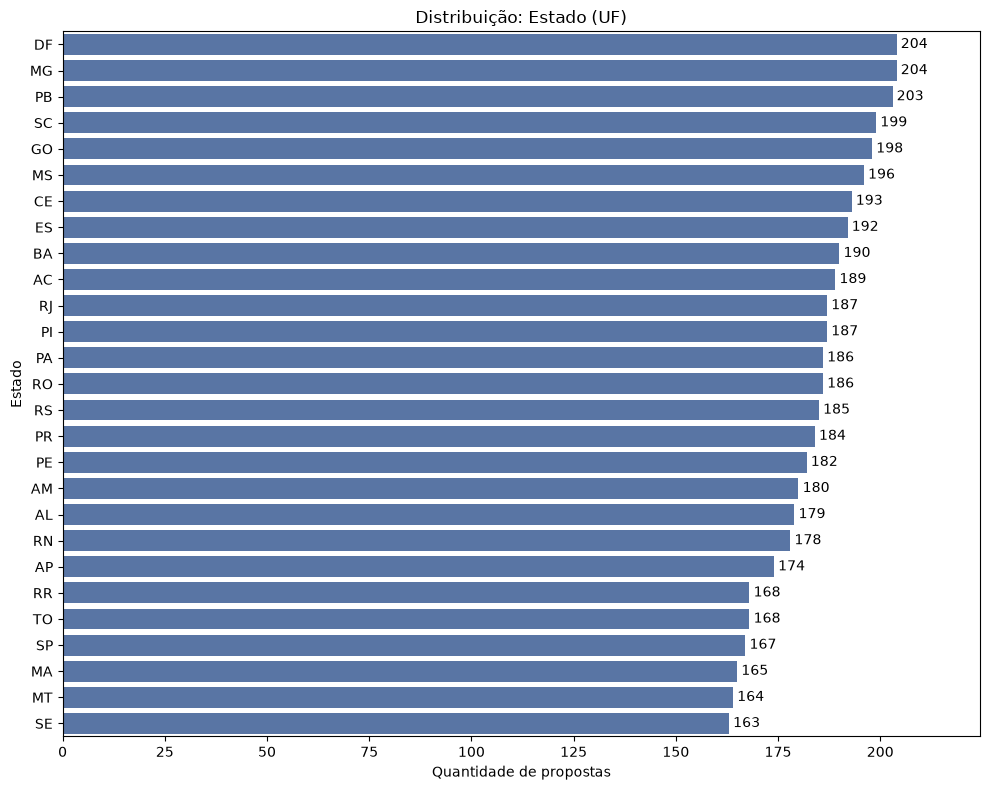

In [28]:
ordem_estado = df_limpo["estado"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 8))
sns.countplot(data=df_limpo, y="estado", order=ordem_estado, ax=ax, color="#4C72B0")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.1)
ax.set_title("Distribuição: Estado (UF)")
ax.set_xlabel("Quantidade de propostas")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()

As propostas estão distribuídas de forma quase uniforme entre os 27 estados (de 163 a 204 cada), sem relação com a população real: São Paulo, por exemplo, tem volume semelhante ao de Roraima. Isso sugere que o estado não carrega informação relevante, o que será verificado na relação com a inadimplência.

### Relação com a inadimplência

Comparação das variáveis numéricas contínuas entre adimplentes e inadimplentes.

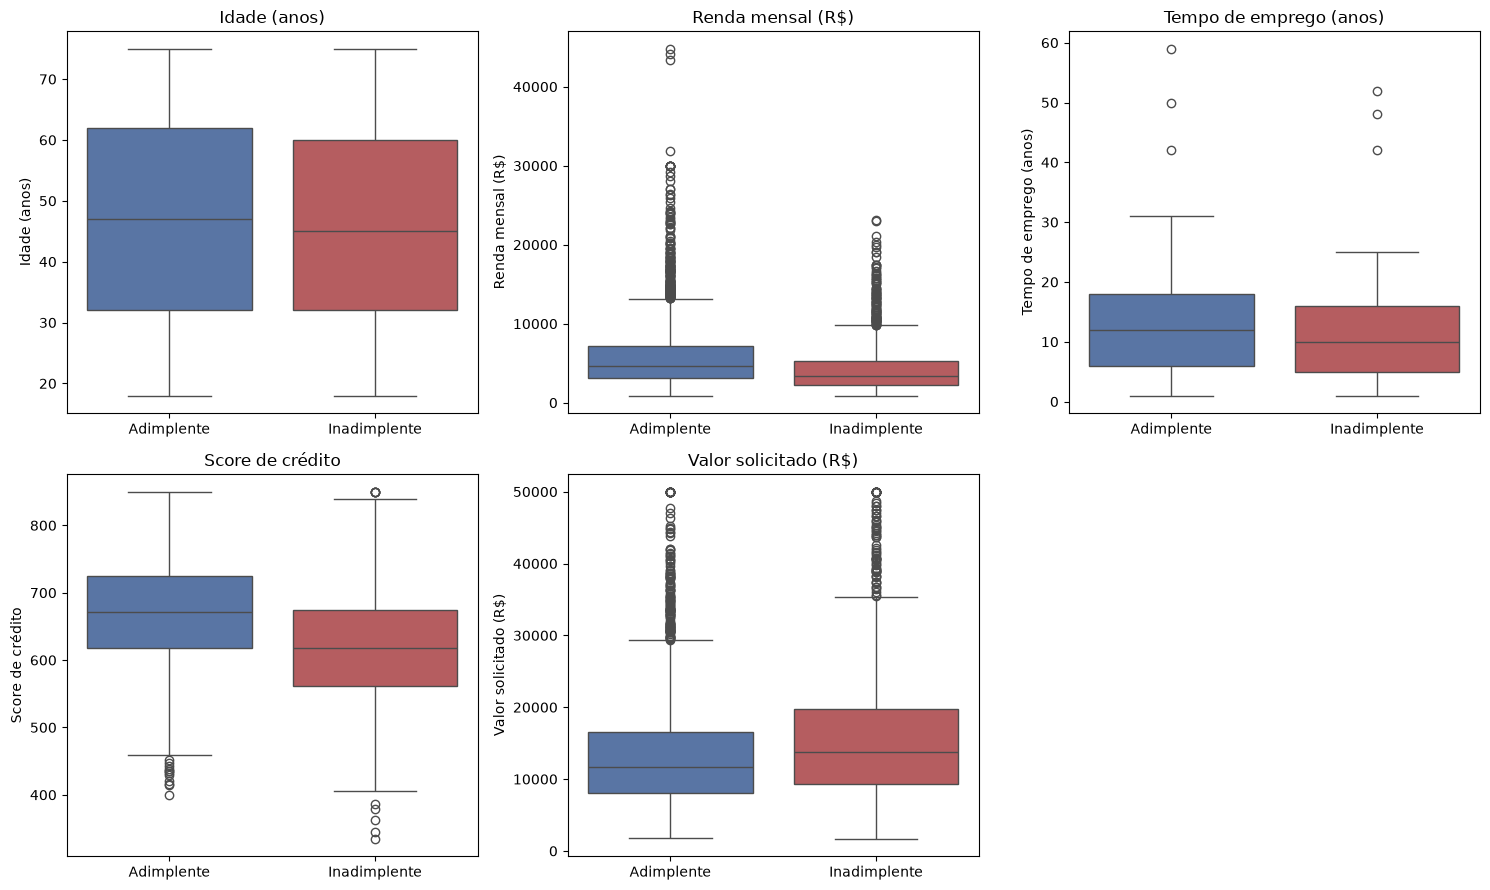

In [29]:
colunas_continuas = ["idade", "renda_mensal", "tempo_emprego_anos", "score_credito", "valor_solicitado"]
cores_alvo = {0: "#4C72B0", 1: "#C44E52"}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, coluna in enumerate(colunas_continuas):
    ax = axes[i]
    sns.boxplot(data=df_limpo, x="inadimplente", y=coluna, hue="inadimplente",
                palette=cores_alvo, legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Adimplente", "Inadimplente"])
    ax.set_title(nomes_variaveis[coluna])
    ax.set_xlabel("")
    ax.set_ylabel(nomes_variaveis[coluna])

axes[5].set_visible(False)

plt.tight_layout()
plt.show()

O score de crédito é a variável que mais diferencia as classes: a mediana dos inadimplentes fica cerca de 50 pontos abaixo da dos adimplentes. Inadimplentes também têm renda menor e pedem valores maiores. O tempo de emprego é um pouco menor entre os inadimplentes, e a idade praticamente não difere entre os grupos.

Mesmo nas variáveis mais relevantes, as distribuições se sobrepõem bastante. Nenhuma variável separa as classes sozinha.

O score de crédito é a variável que mais diferencia as classes: a mediana dos inadimplentes fica cerca de 50 pontos abaixo da dos adimplentes. Inadimplentes também têm renda menor e pedem valores maiores. O tempo de emprego é um pouco menor entre os inadimplentes, e a idade praticamente não difere entre os grupos.

Mesmo nas variáveis mais relevantes, as distribuições se sobrepõem bastante. Nenhuma variável separa as classes sozinha.

Taxa de inadimplência para cada prazo e para cada quantidade de dívidas ativas.

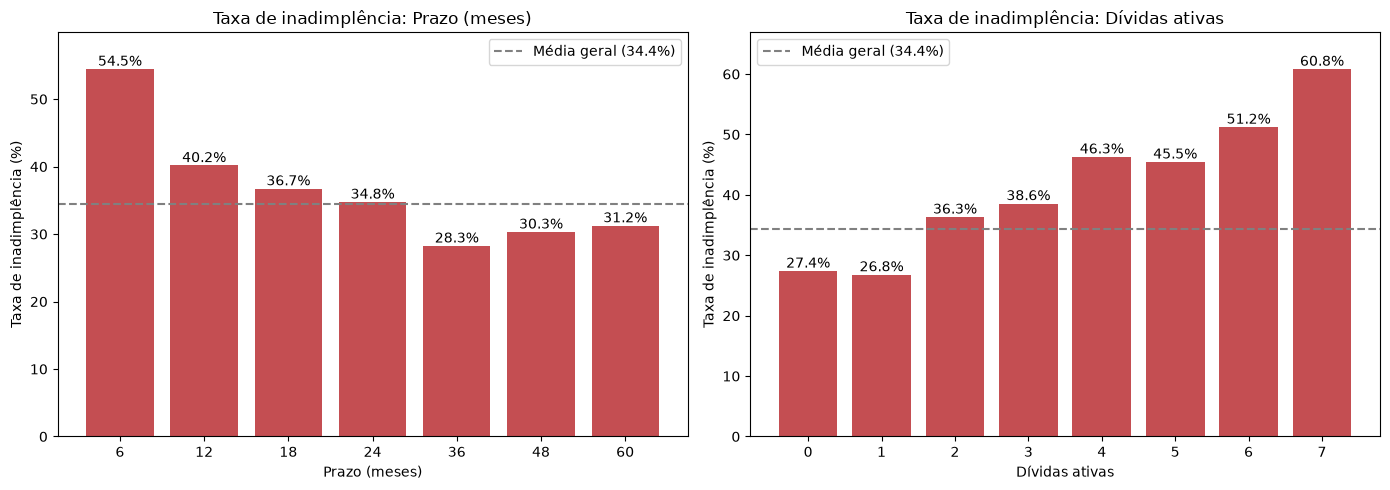

In [30]:
taxa_geral = df_limpo["inadimplente"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, coluna in zip(axes, colunas_discretas):
    taxa = df_limpo.groupby(coluna)["inadimplente"].mean() * 100
    barras = ax.bar(taxa.index.astype(str), taxa.values, color="#C44E52")
    ax.bar_label(barras, fmt="%.1f%%")
    ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1f}%)")
    ax.legend()
    ax.margins(y=0.1)
    ax.set_title(f"Taxa de inadimplência: {nomes_variaveis[coluna]}")
    ax.set_xlabel(nomes_variaveis[coluna])
    ax.set_ylabel("Taxa de inadimplência (%)")

plt.tight_layout()
plt.show()

Prazos curtos têm mais inadimplência: 54,5% em 6 meses, contra 28,3% em 36 meses. Uma hipótese é que prazos curtos geram parcelas altas em relação à renda, o que será investigado na engenharia de atributos. A relação não é linear, já que a taxa volta a subir levemente em 48 e 60 meses.

A inadimplência cresce com o número de dívidas ativas: fica em torno de 27% com 0 ou 1 dívida e chega a 60,8% com 7.

Taxa de inadimplência por escolaridade e por finalidade do crédito.

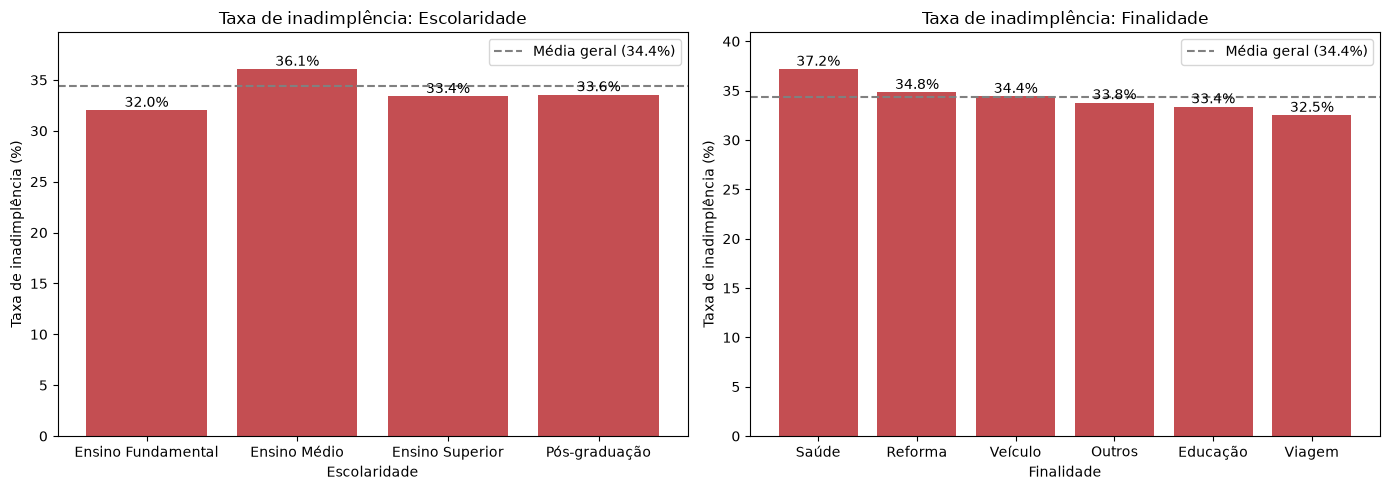

In [31]:
taxa_escolaridade = df_limpo.groupby("escolaridade")["inadimplente"].mean().reindex(ordem_escolaridade) * 100
taxa_finalidade = df_limpo.groupby("finalidade")["inadimplente"].mean().sort_values(ascending=False) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, taxa, titulo in zip(axes, [taxa_escolaridade, taxa_finalidade], ["Escolaridade", "Finalidade"]):
    barras = ax.bar(taxa.index, taxa.values, color="#C44E52")
    ax.bar_label(barras, fmt="%.1f%%")
    ax.axhline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1f}%)")
    ax.legend()
    ax.margins(y=0.1)
    ax.set_title(f"Taxa de inadimplência: {titulo}")
    ax.set_xlabel(titulo)
    ax.set_ylabel("Taxa de inadimplência (%)")

plt.tight_layout()
plt.show()

Escolaridade e finalidade têm pouca relação com a inadimplência. As taxas ficam entre 32% e 37% em todos os grupos, próximas da média geral, e a escolaridade não mostra tendência de queda com o aumento do nível de estudo. Diferenças dessa ordem podem ocorrer por acaso com o volume de cada grupo.

Taxa de inadimplência por estado.

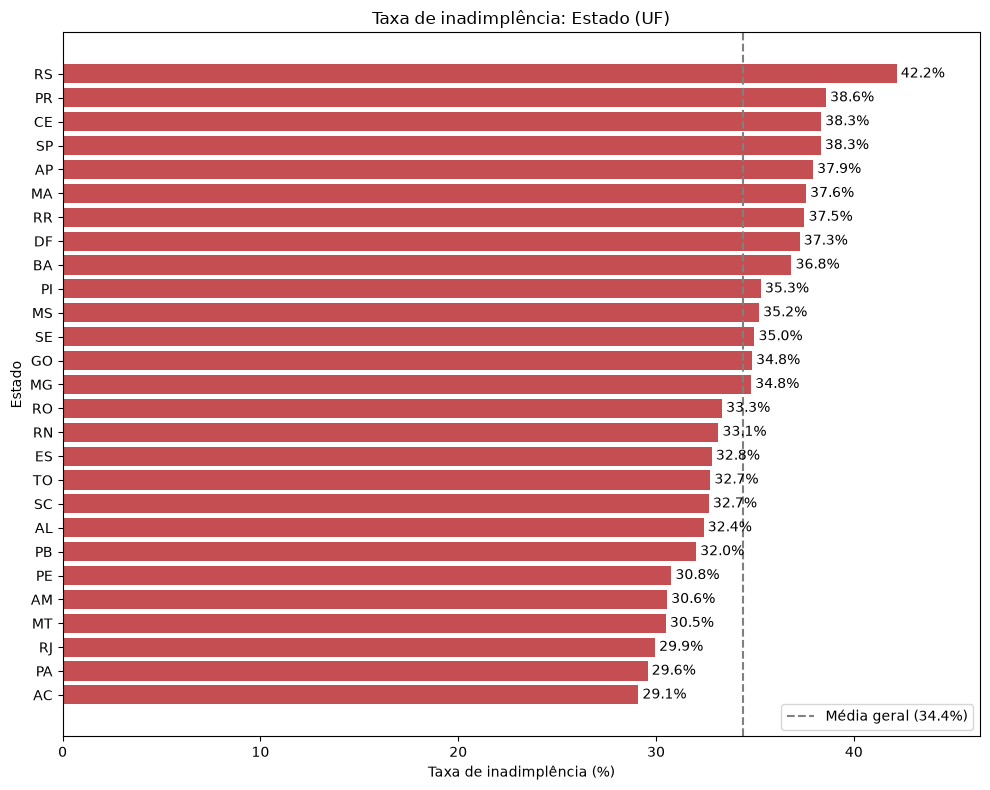

In [32]:
taxa_estado = df_limpo.groupby("estado")["inadimplente"].mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(10, 8))
barras = ax.barh(taxa_estado.index, taxa_estado.values, color="#C44E52")
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.axvline(taxa_geral, color="gray", linestyle="--", label=f"Média geral ({taxa_geral:.1f}%)")
ax.legend(loc="lower right")
ax.margins(x=0.1)
ax.set_title("Taxa de inadimplência: Estado (UF)")
ax.set_xlabel("Taxa de inadimplência (%)")
ax.set_ylabel("Estado")
plt.tight_layout()
plt.show()

As taxas por estado variam de 29,1% a 42,2%, mas, com cerca de 180 clientes por UF, diferenças dessa ordem são compatíveis com o acaso. Não há padrão regional (PR e SC, ou SP e RJ, têm taxas bem diferentes). O estado não mostra relação com a inadimplência.

### Correlações

Correlação entre as variáveis numéricas e o alvo.

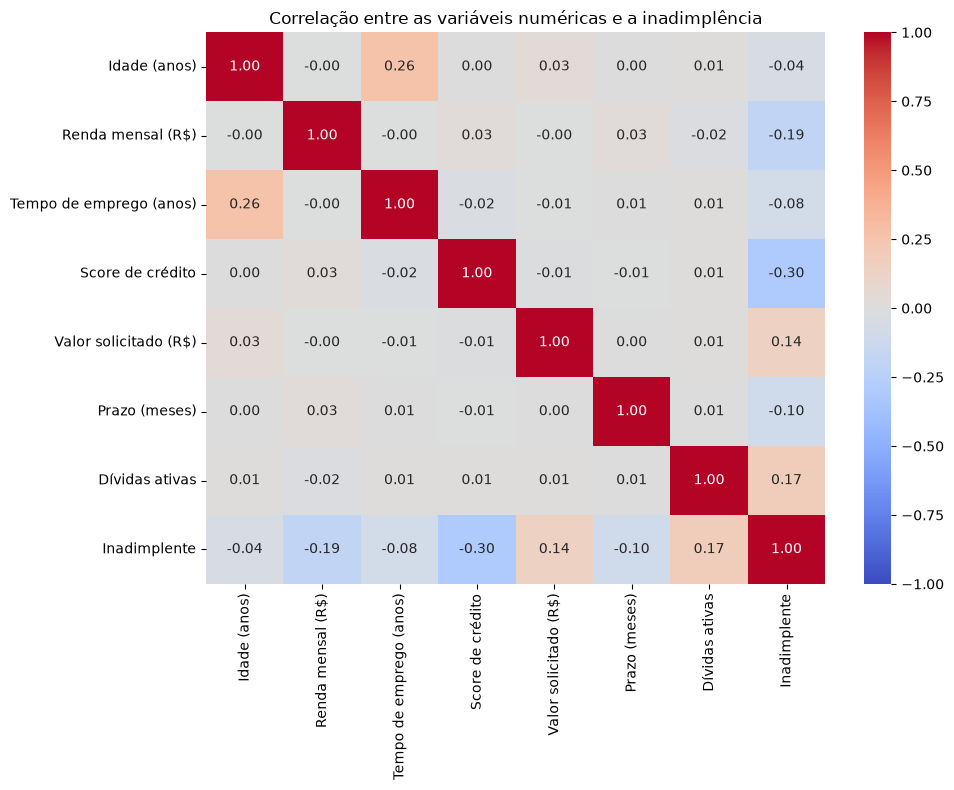

In [34]:
correlacao = df_limpo[colunas_numericas + ["inadimplente"]].corr()
rotulos_corr = [nomes_variaveis.get(c, "Inadimplente") for c in correlacao.columns]

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=rotulos_corr, yticklabels=rotulos_corr, ax=ax)
ax.set_title("Correlação entre as variáveis numéricas e a inadimplência")
plt.tight_layout()
plt.show()

O score de crédito tem a maior correlação com a inadimplência (−0,30), seguido de renda mensal (−0,19), dívidas ativas (+0,17) e valor solicitado (+0,14). Idade e tempo de emprego têm correlação fraca. A correlação do prazo (−0,10) subestima seu efeito, porque a relação não é linear.

Entre as variáveis, a única correlação relevante é entre idade e tempo de emprego (0,26). Renda e valor solicitado não têm correlação entre si, o que reforça a hipótese de que a relação entre parcela e renda traz informação nova.

### Conclusões da análise exploratória

- Alvo: 34,4% de inadimplentes, classes desbalanceadas (quase 2 para 1). A acurácia sozinha não basta para avaliar o modelo.
- Variáveis mais relacionadas à inadimplência: score de crédito, renda mensal, dívidas ativas e valor solicitado.
- Prazo: prazos curtos têm mais inadimplência (54,5% em 6 meses), com relação não linear.
- Relação fraca: tempo de emprego e idade.
- Sem relação aparente: escolaridade, finalidade e estado.
- As variáveis numéricas são quase independentes entre si. A única correlação relevante é entre idade e tempo de emprego.

Pontos para a engenharia de atributos: escalas muito diferentes entre as variáveis, assimetria de renda e valor solicitado, relação entre parcela e renda, e a decisão sobre manter ou não o estado.